# 01. Exploración de datos - Superstore

**Objetivo:** conocer el dataset antes de limpiarlo y modelarlo, y justificar con los datos cuál es la variable objetivo.

En este cuadernillo se revisa: dimensiones, tipos de datos, nulos, duplicados, distribuciones, relación entre ventas, descuentos y ganancias, correlaciones, valores atípicos y el análisis inicial de la variable objetivo.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.carga_datos import cargar_datos
from src.limpieza import contar_atipicos_iqr

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Carga del dataset
El archivo no está en UTF-8, por eso la función de carga usa `latin-1`. Sin eso aparece un error de decodificación.

In [2]:
df = cargar_datos("../data/raw/Sample_-_Superstore.csv")
df.shape

(9994, 21)

## 2. Dimensiones y vista general

In [3]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
df.head()

Filas: 9994
Columnas: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Tipos de datos

In [4]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Las fechas (`Order Date` y `Ship Date`) están como texto, así que hay que convertirlas en la fase de limpieza. `Postal Code` es numérico pero en realidad identifica una ubicación, no es una cantidad.

## 4. Estadísticas descriptivas

In [5]:
columnas_numericas = ["Sales", "Quantity", "Discount", "Profit"]
df[columnas_numericas].describe().round(2)

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


## 5. Valores nulos y duplicados

In [6]:
print("Valores nulos por columna:")
print(df.isnull().sum().sum(), "nulos en total")
print("Registros duplicados:", df.duplicated().sum())

Valores nulos por columna:
0 nulos en total
Registros duplicados: 0


## 6. Distribución de variables numéricas

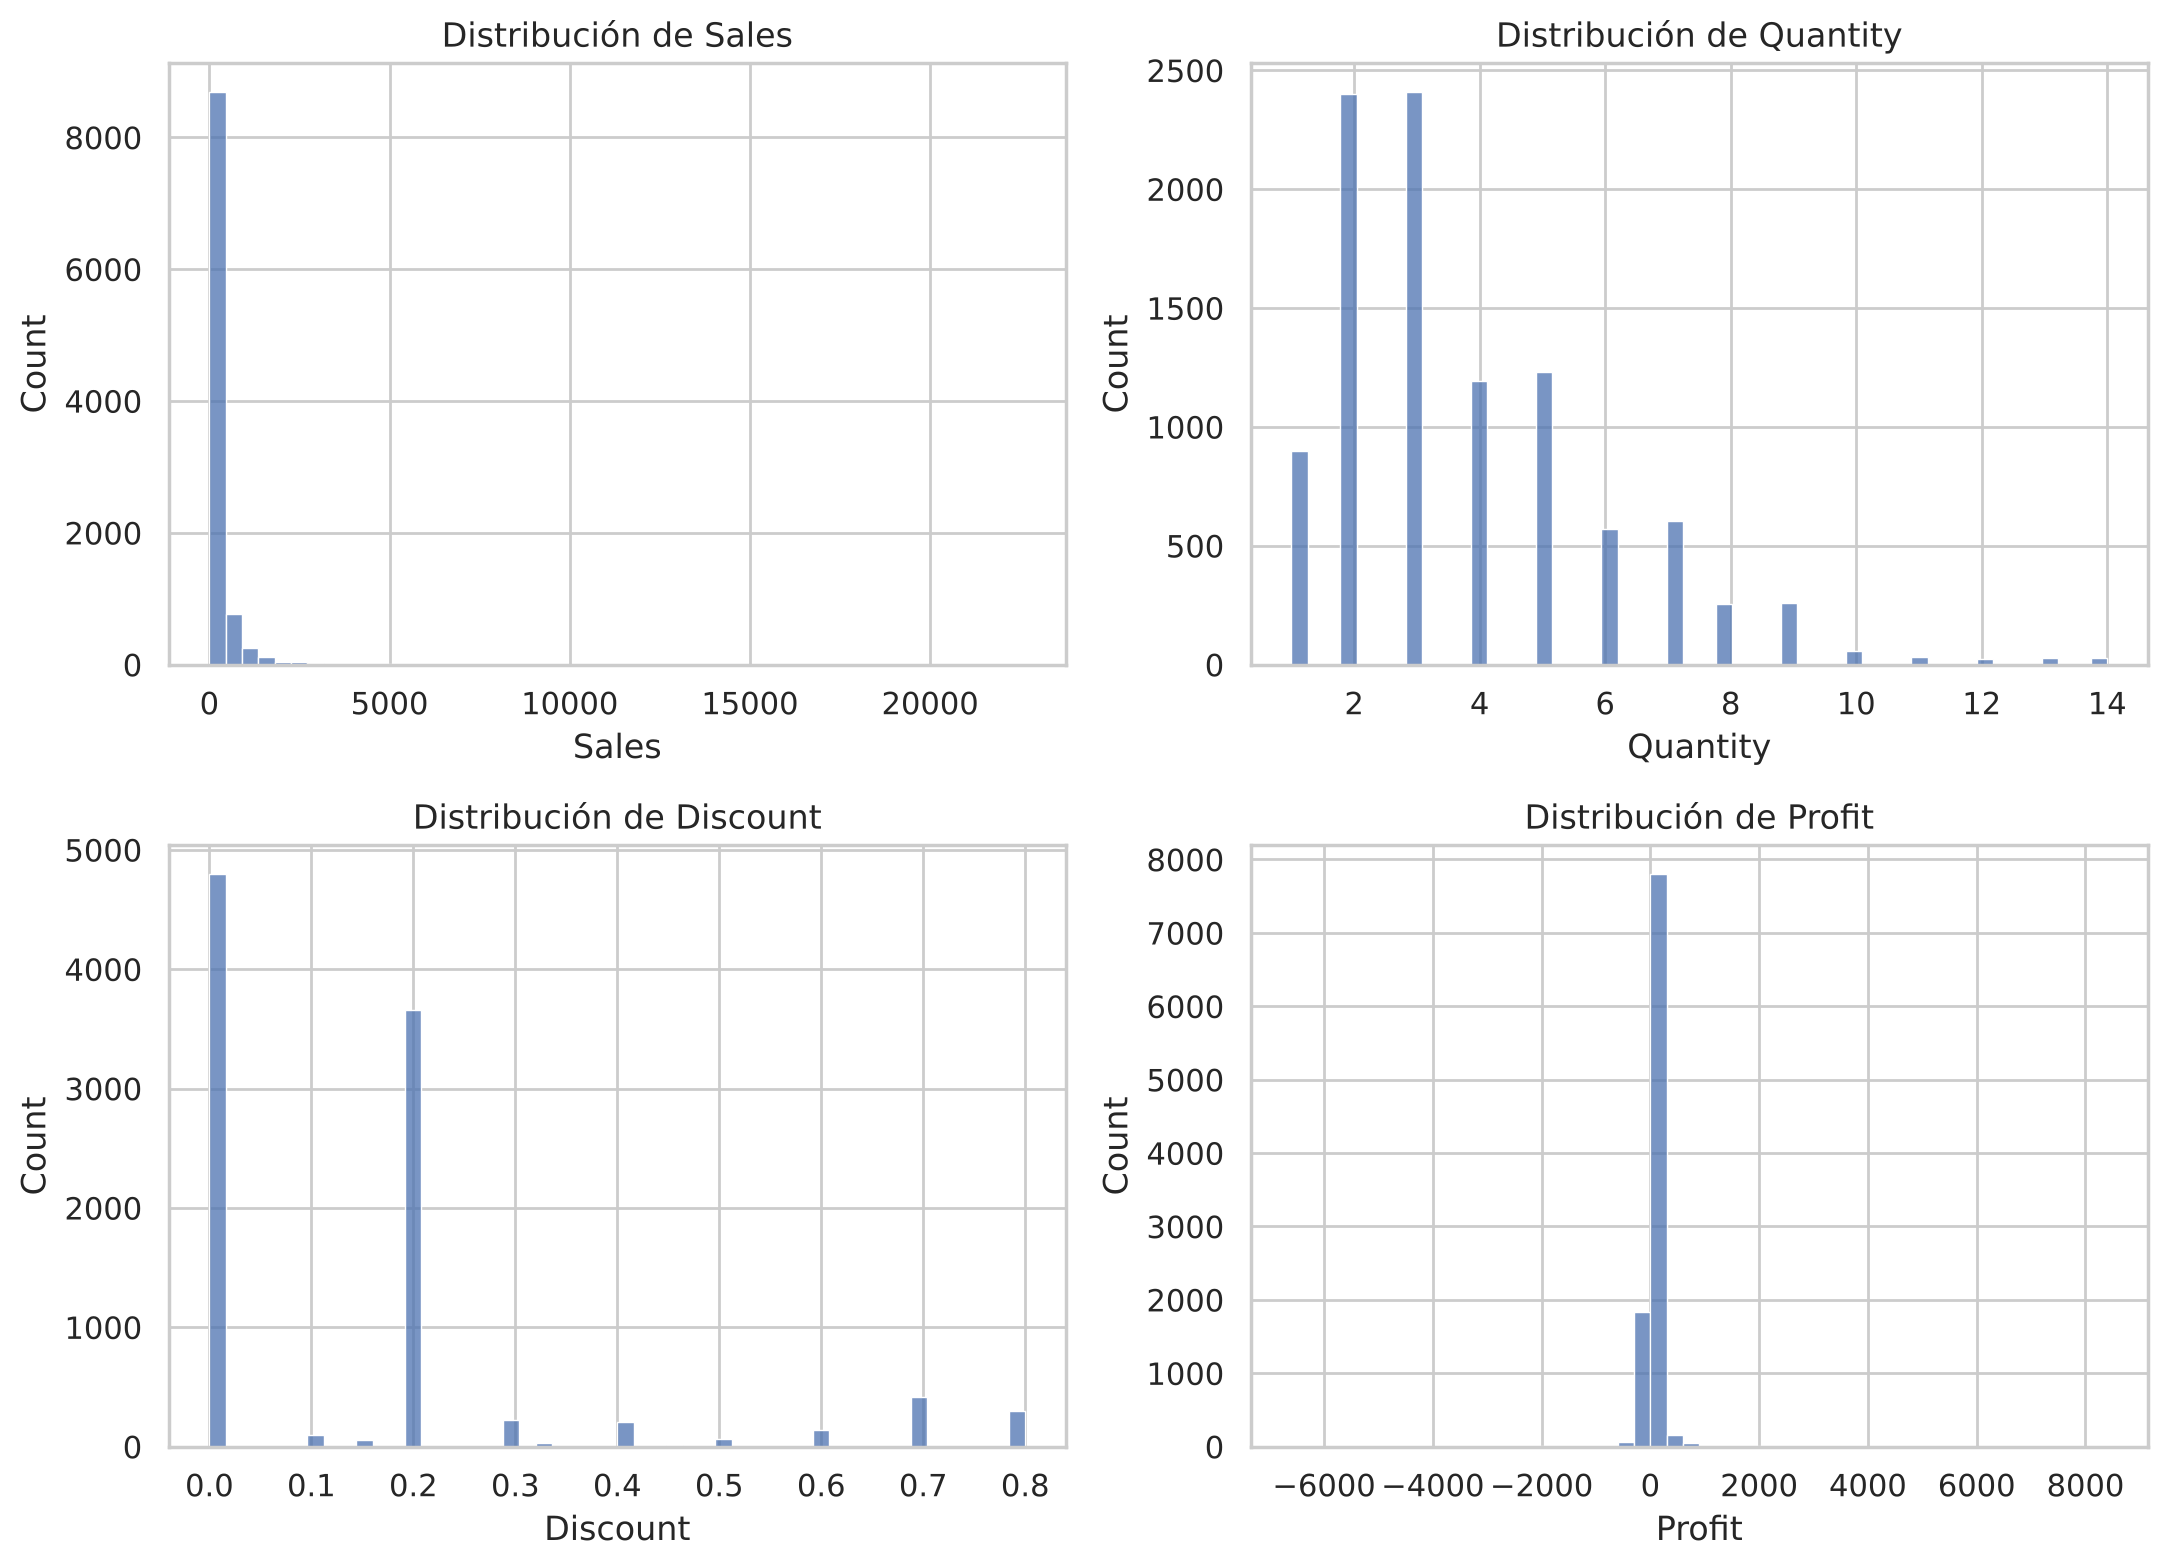

Asimetría (skew):
Sales       12.97
Quantity     1.28
Discount     1.68
Profit       7.56
dtype: float64


In [7]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
for eje, columna in zip(ejes.flatten(), columnas_numericas):
    sns.histplot(df[columna], bins=50, ax=eje)
    eje.set_title(f"Distribución de {columna}")
plt.tight_layout()
plt.show()

print("Asimetría (skew):")
print(df[columnas_numericas].skew().round(2))

## 7. Distribución de variables categóricas

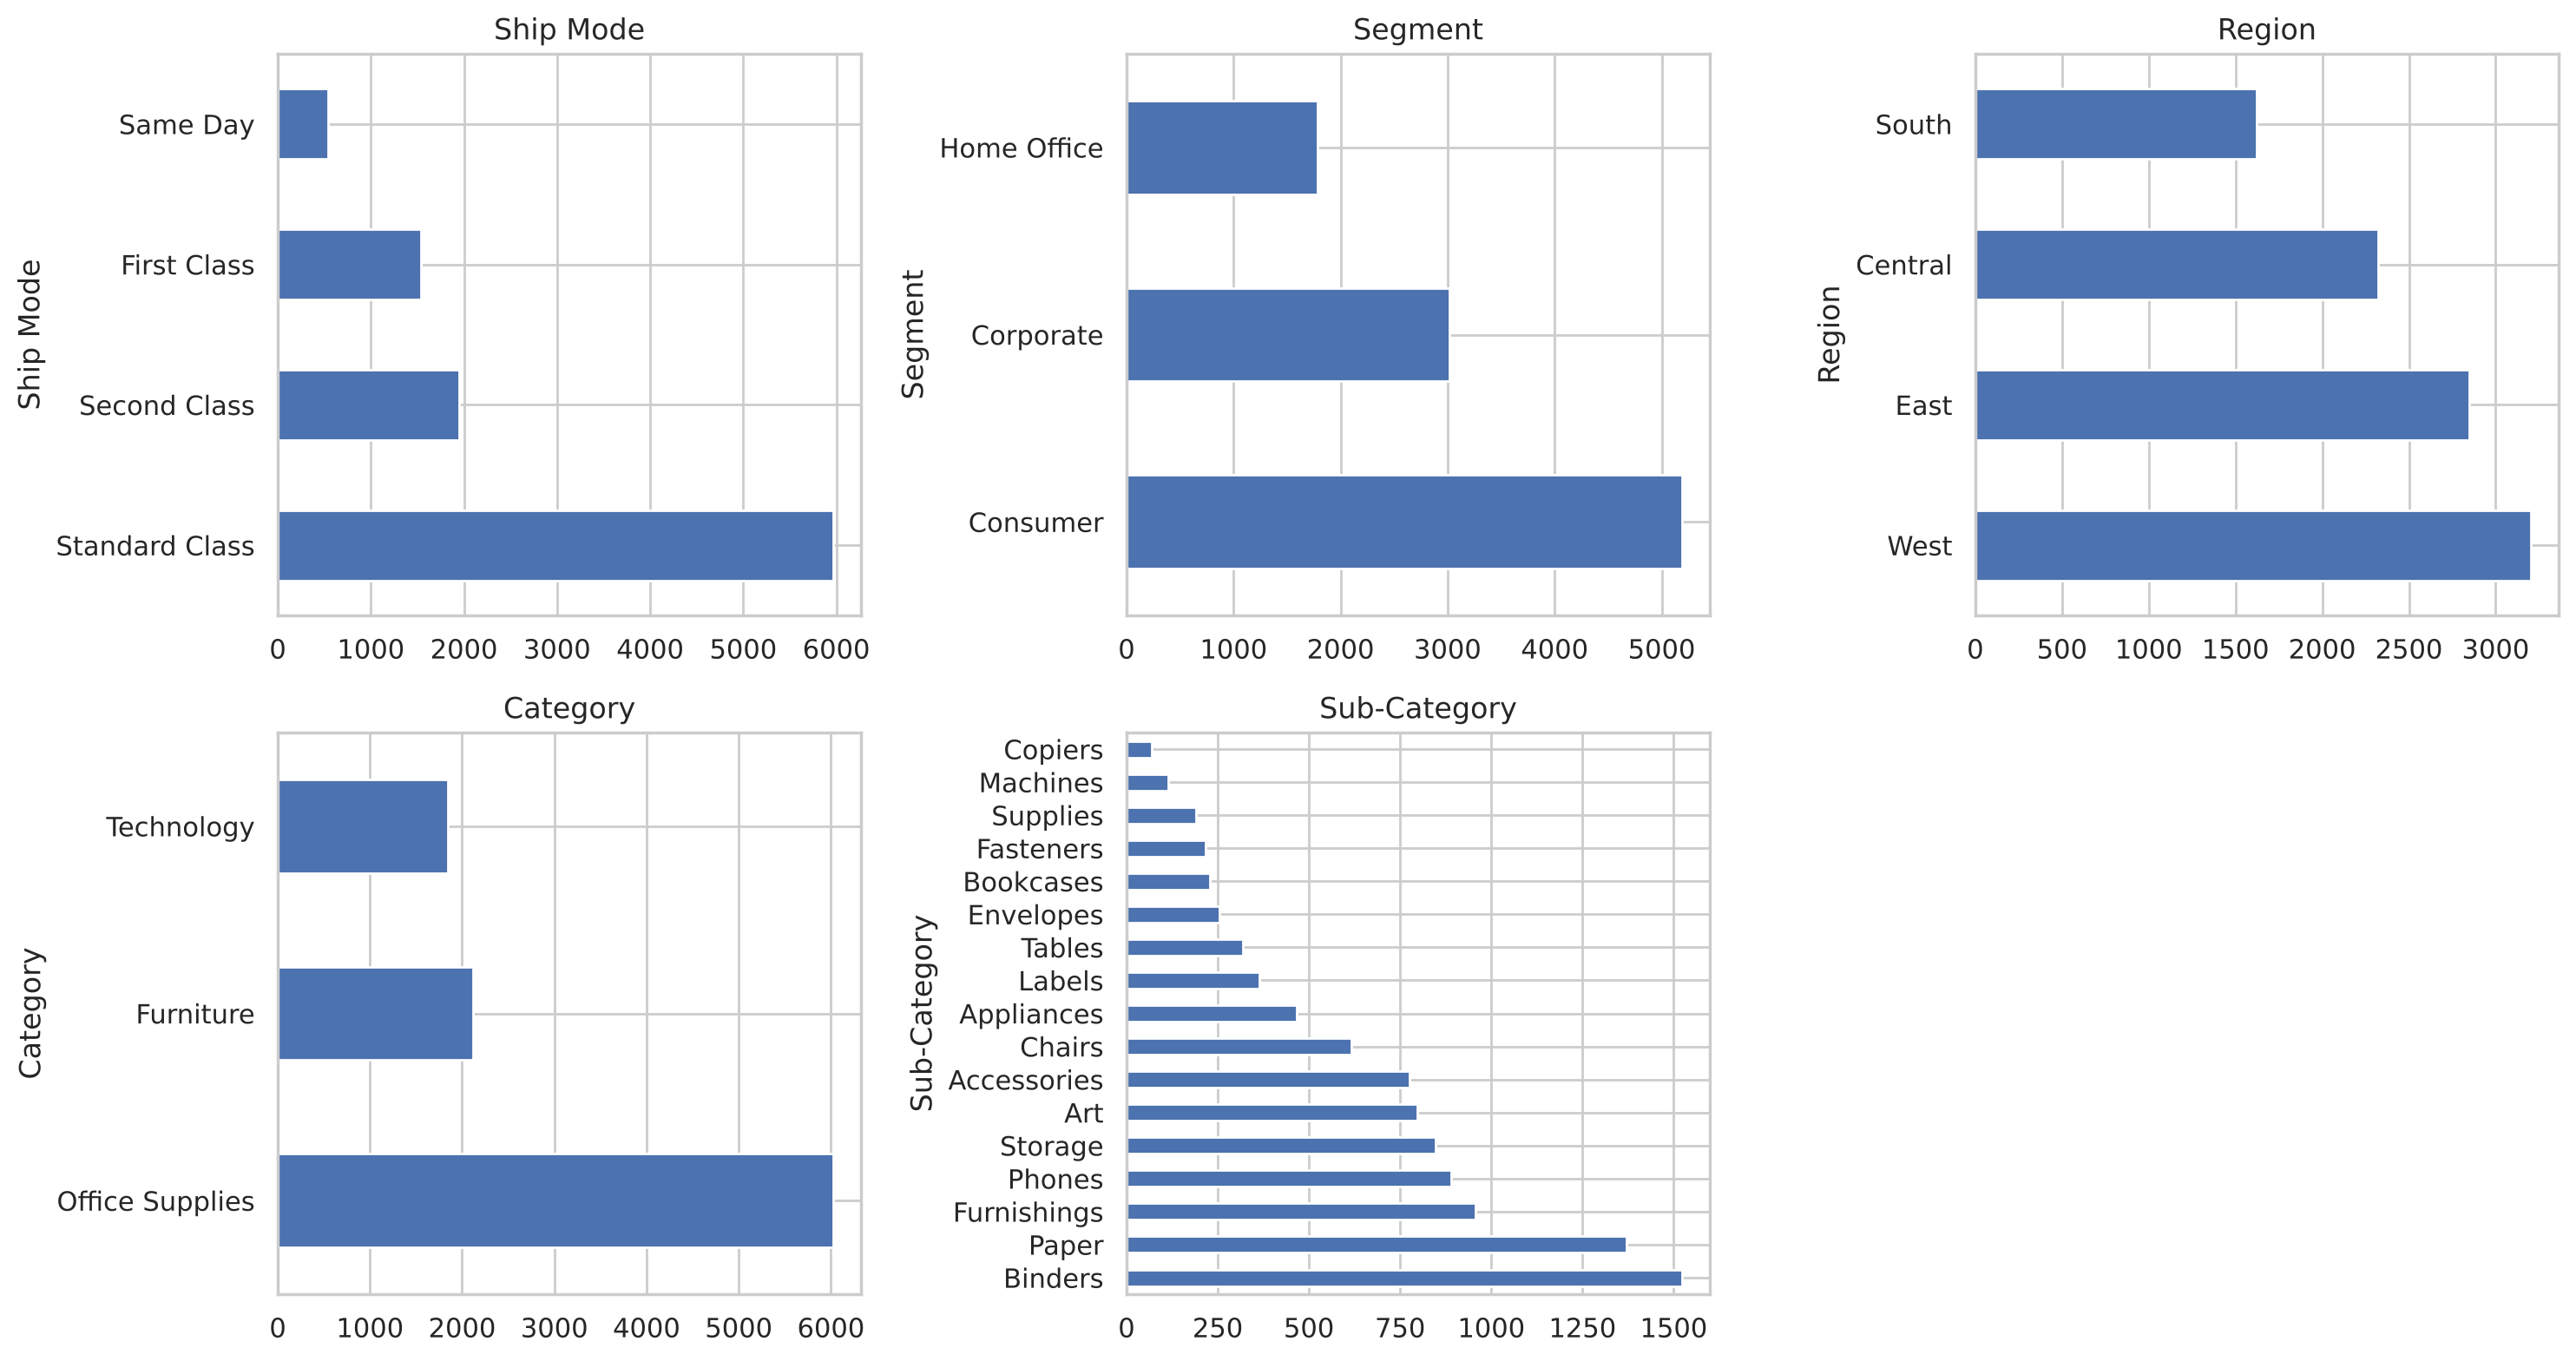

In [8]:
columnas_categoricas = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, columna in zip(ejes.flatten(), columnas_categoricas):
    df[columna].value_counts().plot(kind="barh", ax=eje)
    eje.set_title(columna)
ejes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

In [9]:
print("Valores únicos por columna de texto:")
df.select_dtypes(exclude="number").nunique().sort_values()

Valores únicos por columna de texto:


Country             1
Segment             3
Category            3
Ship Mode           4
Region              4
Sub-Category       17
State              49
City              531
Customer Name     793
Customer ID       793
Order Date       1237
Ship Date        1334
Product Name     1850
Product ID       1862
Order ID         5009
dtype: int64

## 8. Relación entre ventas, descuentos y ganancias

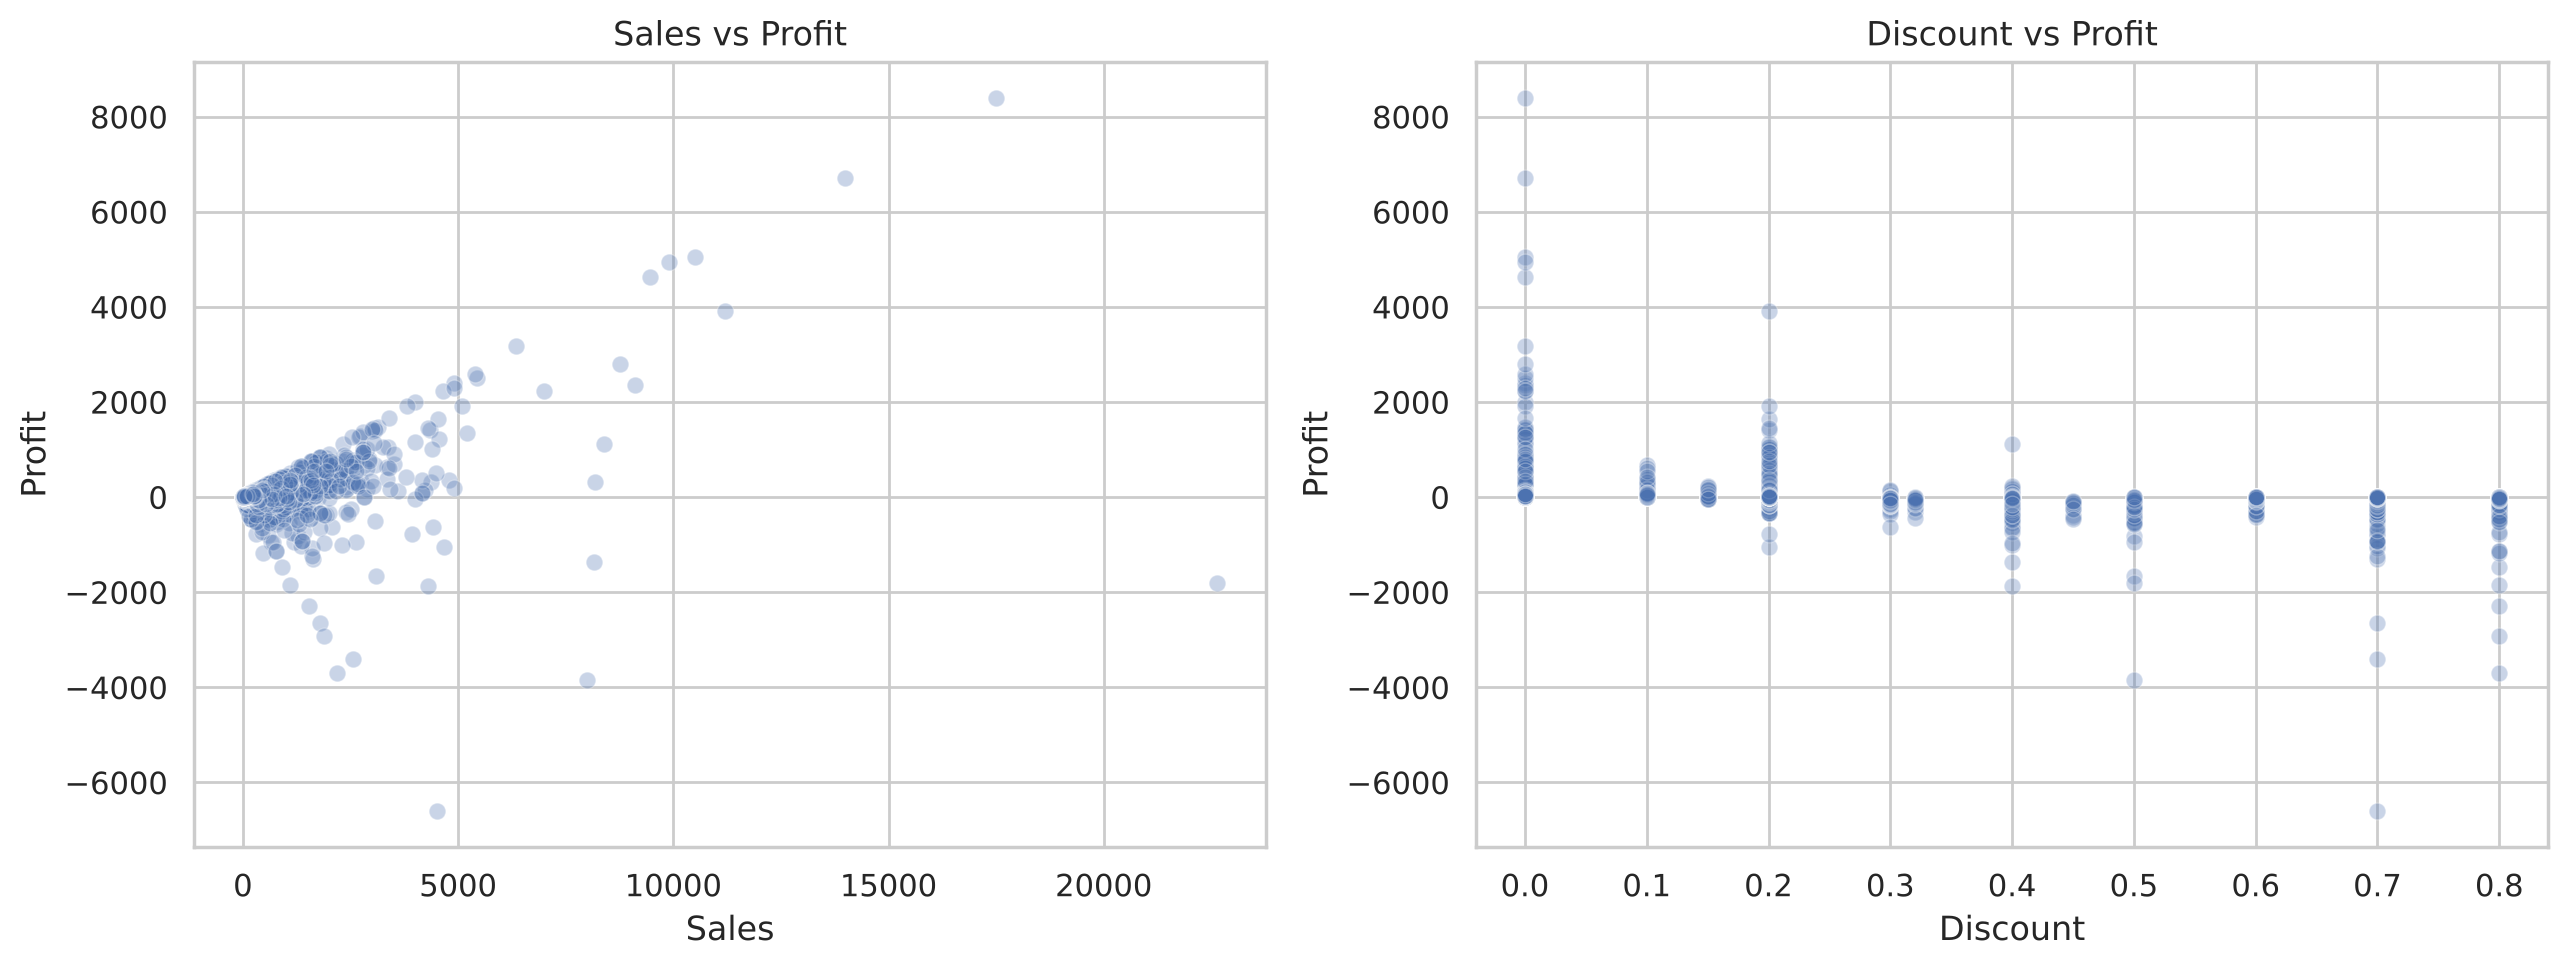

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.3, ax=ejes[0])
ejes[0].set_title("Sales vs Profit")
sns.scatterplot(data=df, x="Discount", y="Profit", alpha=0.3, ax=ejes[1])
ejes[1].set_title("Discount vs Profit")
plt.tight_layout()
plt.show()

In [11]:
resumen_descuento = df.groupby("Discount")["Profit"].agg(["count", "mean"]).round(2)
resumen_descuento

,count,mean
Discount,,
0.00,4798,66.90
0.10,94,96.06
0.15,52,27.29
0.20,3657,24.70
0.30,227,-45.68
0.32,27,-88.56
0.40,206,-111.93
0.45,11,-226.65
0.50,66,-310.70


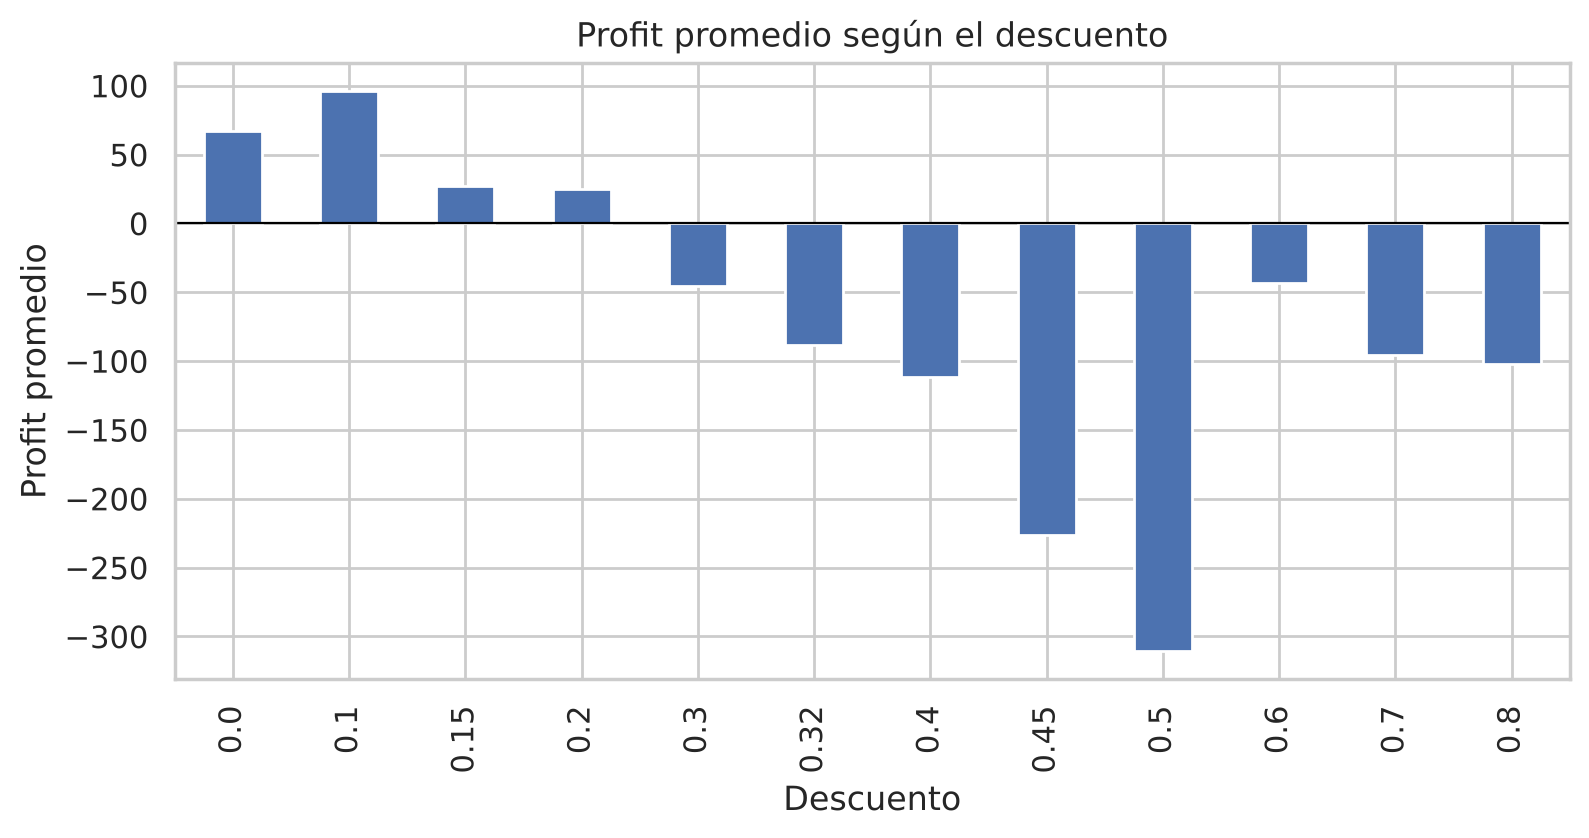

In [12]:
resumen_descuento["mean"].plot(kind="bar", figsize=(9, 4))
plt.title("Profit promedio según el descuento")
plt.xlabel("Descuento")
plt.ylabel("Profit promedio")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

## 9. Matriz de correlación

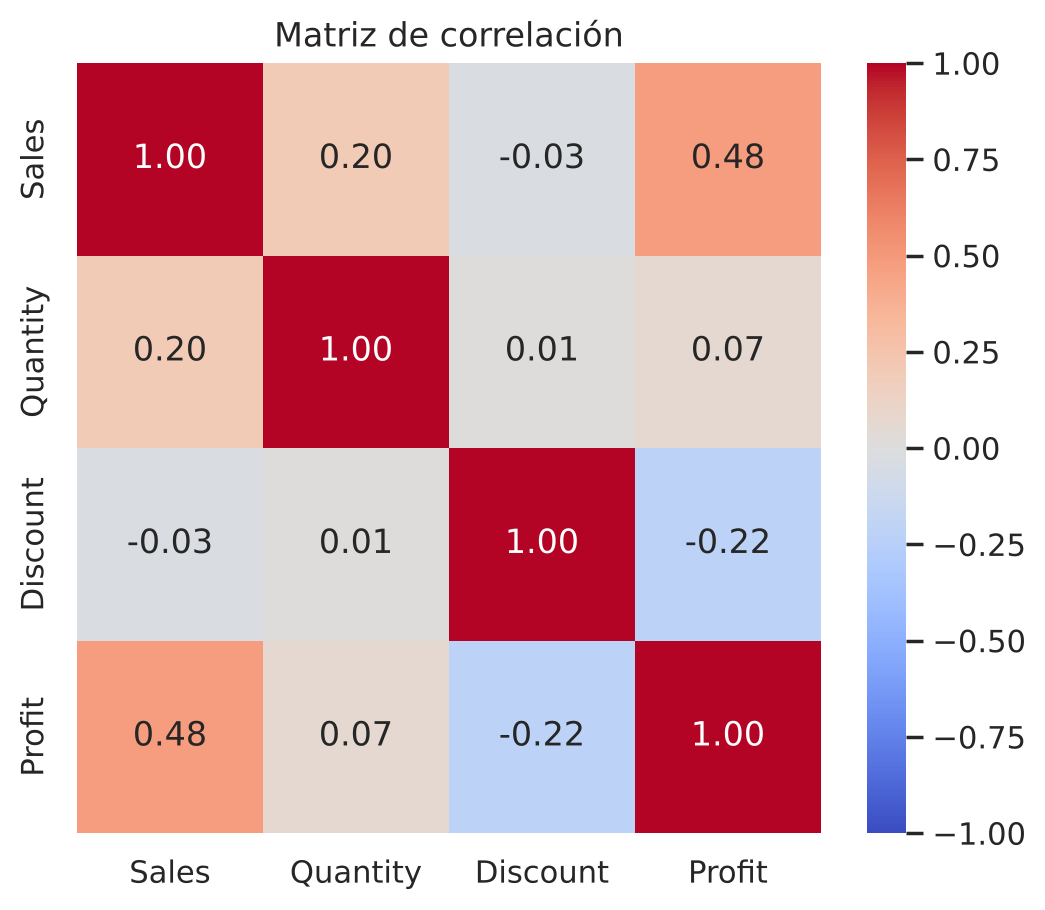

In [13]:
correlacion = df[columnas_numericas].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

## 10. Detección básica de valores atípicos (método IQR)

In [14]:
for columna in columnas_numericas:
    cantidad, inferior, superior = contar_atipicos_iqr(df[columna])
    porcentaje = cantidad / len(df) * 100
    print(f"{columna}: {cantidad} atípicos ({porcentaje:.1f}%), límites [{inferior:.2f}, {superior:.2f}]")

Sales: 1167 atípicos (11.7%), límites [-271.71, 498.93]
Quantity: 170 atípicos (1.7%), límites [-2.50, 9.50]
Discount: 856 atípicos (8.6%), límites [-0.30, 0.50]
Profit: 1881 atípicos (18.8%), límites [-39.72, 70.82]


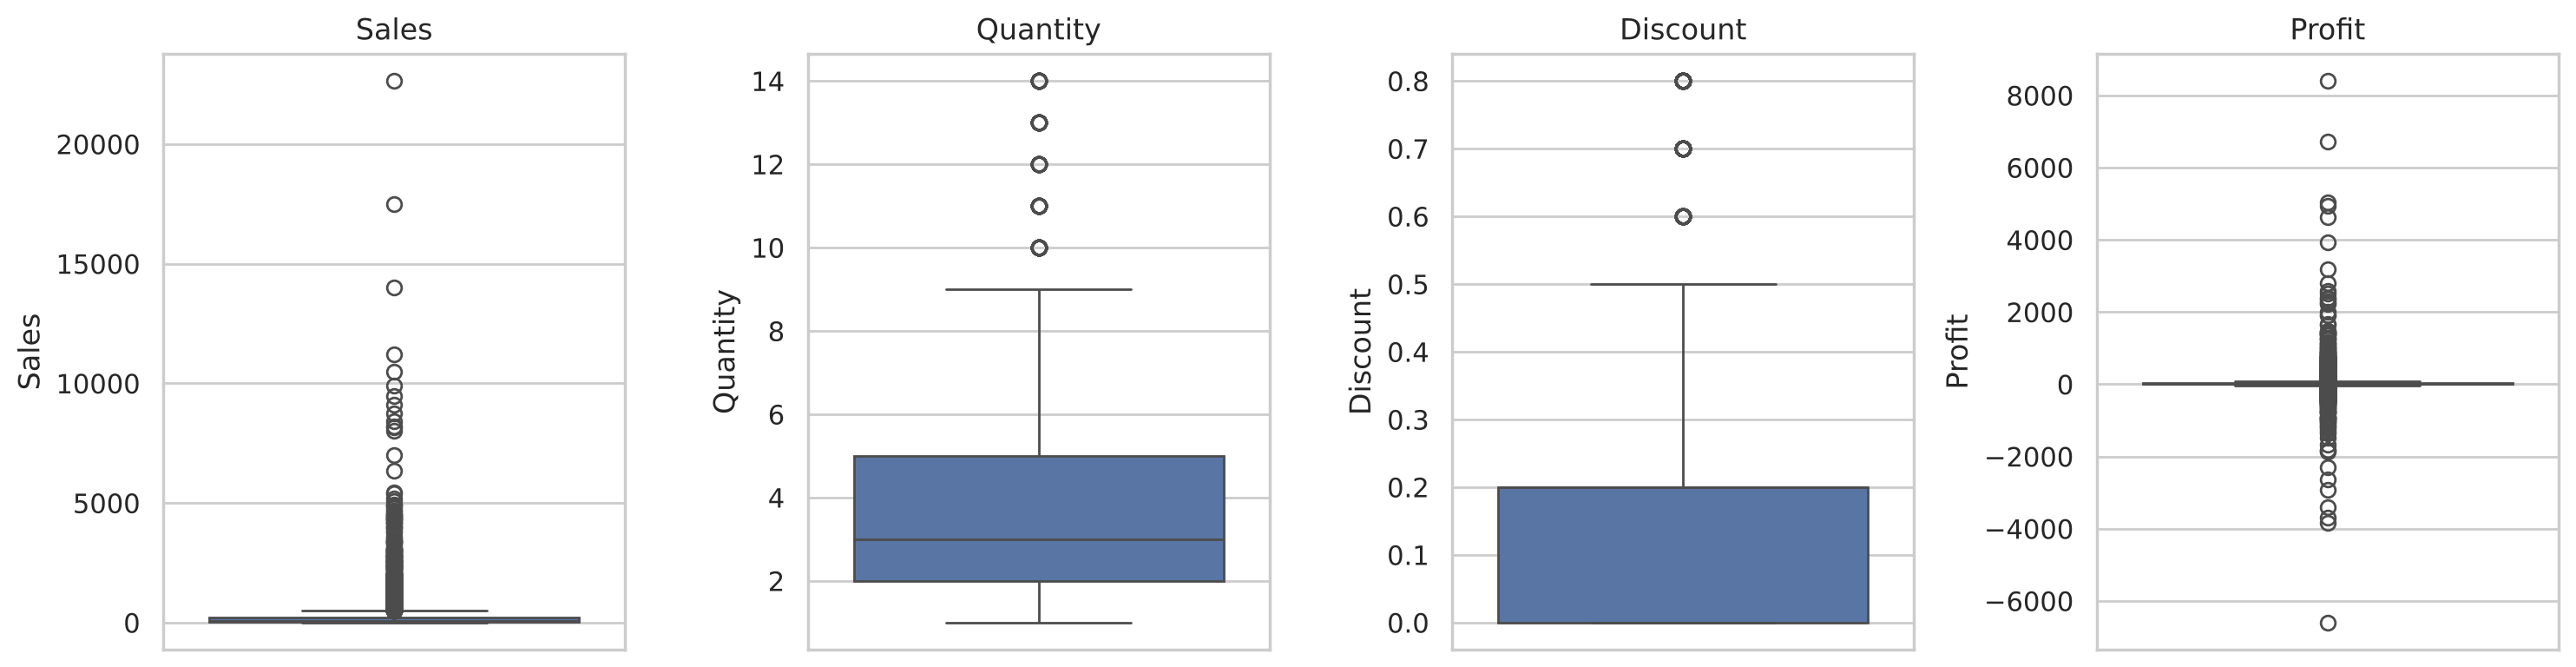

In [15]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for eje, columna in zip(ejes, columnas_numericas):
    sns.boxplot(y=df[columna], ax=eje)
    eje.set_title(columna)
plt.tight_layout()
plt.show()

## 11. Análisis inicial de la variable objetivo

Se evaluaron cuatro candidatas. La decisión se toma con lo que muestran los datos.

In [16]:
print("Valores distintos de Discount:", df["Discount"].nunique())
print("Valores distintos de Profit:", df["Profit"].nunique())
print()
print("Correlación de cada variable numérica con Profit:")
print(correlacion["Profit"].drop("Profit").round(3))

Valores distintos de Discount: 12
Valores distintos de Profit: 7287

Correlación de cada variable numérica con Profit:
Sales       0.479
Quantity    0.066
Discount   -0.219
Name: Profit, dtype: float64


In [17]:
perdidas = (df["Profit"] < 0).mean() * 100
print(f"Registros con pérdida (Profit < 0): {perdidas:.1f}%")
print(f"Profit promedio: {df['Profit'].mean():.2f}")
print(f"Profit mediana: {df['Profit'].median():.2f}")
print(f"Profit mínimo: {df['Profit'].min():.2f}")
print(f"Profit máximo: {df['Profit'].max():.2f}")

Registros con pérdida (Profit < 0): 18.7%
Profit promedio: 28.66
Profit mediana: 8.67
Profit mínimo: -6599.98
Profit máximo: 8399.98


In [18]:
rentabilidad_categoria = df.groupby("Sub-Category")["Profit"].agg(["count", "mean", "sum"]).round(2)
rentabilidad_categoria.sort_values("sum")

,count,mean,sum
Sub-Category,,,
Tables,319,-55.57,-17725.48
Bookcases,228,-15.23,-3472.56
Supplies,190,-6.26,-1189.10
Fasteners,217,4.38,949.52
Machines,115,29.43,3384.76
Labels,364,15.24,5546.25
Art,796,8.20,6527.79
Envelopes,254,27.42,6964.18
Furnishings,957,13.65,13059.14


## 12. Conclusiones de la exploración

**Calidad de los datos.** El dataset tiene 9.994 registros y 21 columnas. No tiene valores nulos ni filas duplicadas, así que la limpieza se va a concentrar en otros puntos: las fechas están como texto, hay columnas que no sirven para predecir y hay valores extremos. También noté que hay 5.009 pedidos distintos para casi 10.000 filas, es decir, un mismo pedido aparece en varias filas. Esto lo tengo que tener en cuenta al separar train y test.

**Columnas poco útiles.** `Country` tiene un solo valor, `Row ID` es solo un consecutivo, y `Customer Name`, `Customer ID`, `Product Name` y `Product ID` tienen demasiados valores distintos (más de 790) para codificarlos de forma sencilla. `City` (531 valores) tiene el mismo problema.

**Distribuciones.** `Sales` y `Profit` están muy sesgadas hacia la derecha (asimetría de 12,97 y 7,56). La mayoría de las ventas son pequeñas (mediana de 54,49) y pocas son muy grandes (máximo de 22.638). Casi la mitad de los registros (4.798) no tiene descuento y 3.657 tienen un descuento del 20%.

**Ventas, descuentos y ganancias.** `Sales` y `Profit` tienen correlación positiva moderada (0,48): a mayor venta, tiende a haber mayor ganancia. `Discount` y `Profit` tienen correlación negativa (-0,22), pero la tabla por descuento muestra algo que la correlación no alcanza a mostrar: con descuentos de 0% a 20% el Profit promedio es positivo, y desde 30% pasa a ser negativo (por ejemplo, -310,70 con 50%). Entonces la relación no es una línea recta sino que cambia de comportamiento. `Quantity` casi no se relaciona con Profit (0,07).

**Valores atípicos.** Según el método IQR, `Profit` tiene 18,8% de valores atípicos y `Sales` 11,7%. Son porcentajes altos, lo que indica que la distribución tiene colas largas y no que haya errores de digitación. Por ejemplo, los Profit extremos corresponden a ventas grandes reales, como las de los copiers, que son la subcategoría con mayor ganancia promedio (817,91).

**Variable objetivo.** Elijo **`Profit`** por estas razones: (1) es continua (7.287 valores distintos), por lo que el problema es de regresión; (2) tiene sentido de negocio, porque permite saber qué ventas dejan ganancia y cuáles dejan pérdida, y el 18,7% de los registros tiene pérdida; (3) tiene relación con otras variables, pero no tan fuerte como para que el problema sea trivial; (4) `Discount` no se eligió porque solo tiene 12 valores distintos y `Sales` se decide antes de conocer el resultado del negocio, así que es mejor usarla como variable predictora.

**Decisiones para la siguiente fase.** No voy a crear variables a partir de `Profit` (como el margen) porque sería fuga de datos. Tampoco voy a eliminar los valores extremos de `Profit`, porque son transacciones reales; en `Sales` voy a aplicar una transformación logarítmica para reducir el efecto de los extremos.